In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your file
df = pd.read_csv(r"D:\College\Research\\Astrophysics\ProjectTry\yolo-dagn\gothic_catalog.csv")

# Quick check
print(df.head())
print(df.columns)

          ObjID     SpecObjID         RA        DEC  Redshift  dist_arcsec  \
0  1.237659e+18  1.174429e+18  206.62798  53.890795  0.439151    15.385007   
1  1.237661e+18  1.459342e+18  126.91165   6.520355  0.655582     9.322929   
2  1.237661e+18  1.466018e+18  139.40197   9.306186  0.653258     9.115071   
3  1.237668e+18  2.740571e+18  136.19104  14.591238  0.488312    11.502688   
4  1.237658e+18  9.896867e+17  173.28083  51.387976  0.443278    12.086268   

    dist_kpc  delta_s_kpc  gothic_dist_arcsec  gothic_delta_s_kpc  
0  87.375675   138.404190           13.169081           91.346766  
1  64.838371   125.203746            6.077663           82.634473  
2  63.296463   121.978357            5.834510           80.505716  
3  69.327960   115.062570            8.627545           75.941296  
4  69.012611   109.750416            9.310216           72.435274  
Index(['ObjID', 'SpecObjID', 'RA', 'DEC', 'Redshift', 'dist_arcsec',
       'dist_kpc', 'delta_s_kpc', 'gothic_dist_arcsec'

In [38]:

# Data cleaning with required methodology
arc_bad =  df.loc[df['gothic_dist_arcsec'].fillna(1) <= 0, ['ObjID']]
kpc_bad =  df.loc[df['gothic_delta_s_kpc'].fillna(1) <= 0, ['ObjID']]

print("Arcsec invalid objIDs:")
print(arc_bad['ObjID'])
print("Kpc invalid objIDs:")
print(kpc_bad['ObjID'])

df_arc = df[df['gothic_dist_arcsec']>0].copy()
df_kpc = df[df['gothic_delta_s_kpc']>0].copy()


Arcsec invalid objIDs:
3119     1.237656e+18
5124     1.237653e+18
5521     1.237655e+18
6443     1.237665e+18
28754    1.237663e+18
Name: ObjID, dtype: float64
Kpc invalid objIDs:
29465    1.237654e+18
29466    1.237651e+18
29467    1.237655e+18
29468    1.237656e+18
29469    1.237657e+18
             ...     
29600    1.237663e+18
29601    1.237666e+18
29602    1.237662e+18
29603    1.237664e+18
29604    1.237665e+18
Name: ObjID, Length: 140, dtype: float64


In [39]:
# Number of bins
bin_width = 0.25
bins = np.arange(0, df['gothic_dist_arcsec'].max() + bin_width, bin_width)
# bins_arcsec = 20

# Calculate histogram
freq_arcsec, edges_arcsec = np.histogram(
    df['gothic_dist_arcsec'].dropna(),
    bins=bins
)

cumfreq_arcsec = np.cumsum(freq_arcsec)

# Statistics table
arcsec_table = pd.DataFrame({
    'Bin Left Edge': edges_arcsec[:-1],
    'Bin Right Edge': edges_arcsec[1:],
    'Frequency': freq_arcsec,
    'Cumulative Frequency': cumfreq_arcsec
})

arcsec_table

,Bin Left Edge,Bin Right Edge,Frequency,Cumulative Frequency
0,0.00,0.25,11,11
1,0.25,0.50,19,30
2,0.50,0.75,39,69
3,0.75,1.00,64,133
4,1.00,1.25,133,266
...,...,...,...,...
84,21.00,21.25,1,29603
85,21.25,21.50,0,29603
86,21.50,21.75,1,29604
87,21.75,22.00,0,29604


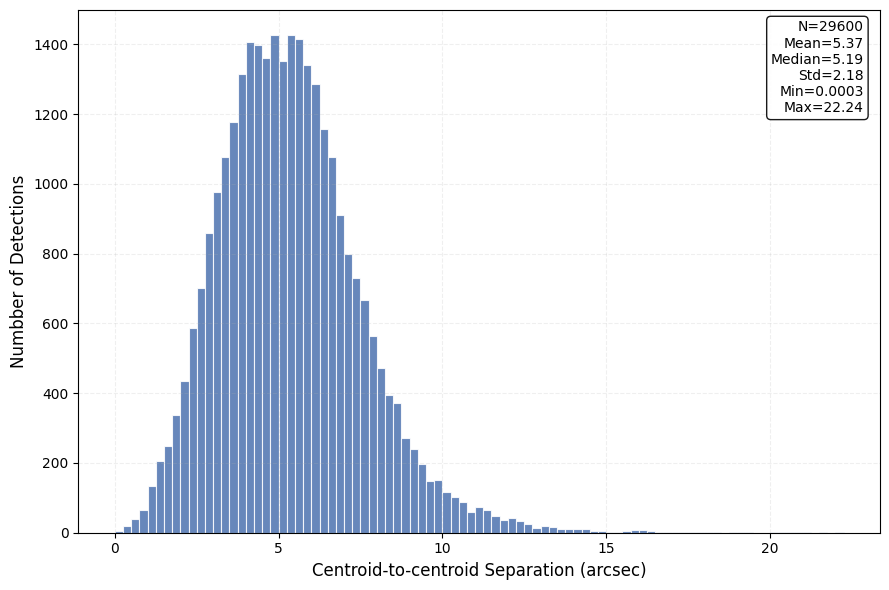

In [40]:

import matplotlib.pyplot as plt
data=df_arc['gothic_dist_arcsec'].dropna()
fig,ax=plt.subplots(figsize=(9,6))
n,b,_=ax.hist(data,bins=bins,color='#4C72B0',alpha=0.85,edgecolor='white',linewidth=0.8)
ax.set_xlabel('Centroid-to-centroid Separation (arcsec)',fontsize=12)
ax.set_ylabel('Numbber of Detections',fontsize=12)
# ax.set_title('Distribution of GOTHIC Separation',weight='bold')
ax.grid(alpha=.2,ls='--')
stats=f"N={len(data)}\nMean={data.mean():.2f}\nMedian={data.median():.2f}\nStd={data.std():.2f}\nMin={data.min():.4f}\nMax={data.max():.2f}"
ax.text(.98,.98,stats,transform=ax.transAxes,ha='right',va='top',bbox=dict(boxstyle='round',fc='white',alpha=.9))
plt.tight_layout();plt.show()


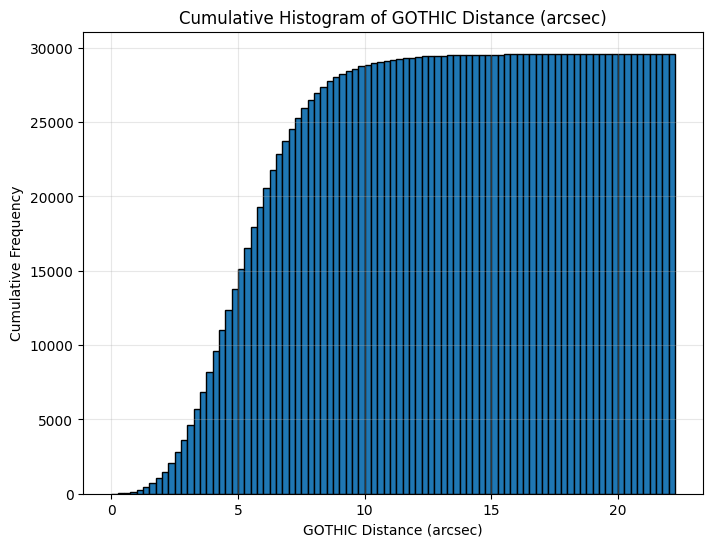

In [41]:
plt.figure(figsize=(8,6))

plt.hist(
    df['gothic_dist_arcsec'].dropna(),
    bins=bins,
    cumulative=True,
    edgecolor='black'
)

plt.xlabel('GOTHIC Distance (arcsec)')
plt.ylabel('Cumulative Frequency')
plt.title('Cumulative Histogram of GOTHIC Distance (arcsec)')
plt.grid(alpha=0.3)

plt.show()

In [42]:
arcsec_table.to_csv(
    "gothic_arcsec_frequency_table.csv",
    index=False
)

print("Saved gothic_arcsec_frequency_table.csv")

Saved gothic_arcsec_frequency_table.csv


In [43]:
# Keep only non-negative values
kpc_data = df.loc[df['gothic_delta_s_kpc'] >= 0, 'gothic_delta_s_kpc'].dropna()

bin_width = 1
bins = np.arange(0, kpc_data.max() + bin_width, bin_width)

# Histogram statistics
# Frequencies
freq, edges = np.histogram(kpc_data, bins=bins)
cumfreq= np.cumsum(freq)

# Table
kpc_table = pd.DataFrame({
    'Bin Start (kpc)': edges[:-1],
    'Bin End (kpc)': edges[1:],
    'Frequency': freq,
    'Cumulative Frequency': cumfreq
})

display(kpc_table)

,Bin Start (kpc),Bin End (kpc),Frequency,Cumulative Frequency
0,0.0,1.0,284,284
1,1.0,2.0,303,587
2,2.0,3.0,689,1276
3,3.0,4.0,1265,2541
4,4.0,5.0,1505,4046
...,...,...,...,...
87,87.0,88.0,0,29536
88,88.0,89.0,0,29536
89,89.0,90.0,0,29536
90,90.0,91.0,0,29536


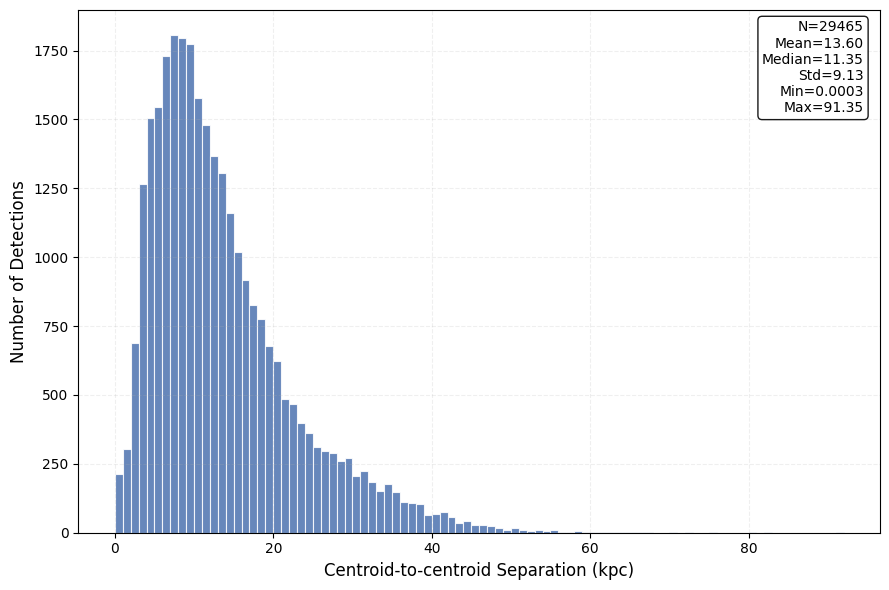

In [44]:

import matplotlib.pyplot as plt
data=df_kpc['gothic_delta_s_kpc'].dropna()
fig,ax=plt.subplots(figsize=(9,6))
n,b,_=ax.hist(data,bins=bins,color='#4C72B0',alpha=0.85,edgecolor='white',linewidth=0.8)
ax.set_xlabel('Centroid-to-centroid Separation (kpc)',fontsize=12)
ax.set_ylabel('Number of Detections',fontsize=12)
# ax.set_title('Distribution of GOTHIC Δs',weight='bold')
ax.grid(alpha=.2,ls='--')
stats=f"N={len(data)}\nMean={data.mean():.2f}\nMedian={data.median():.2f}\nStd={data.std():.2f}\nMin={data.min():.4f}\nMax={data.max():.2f}"
ax.text(.98,.98,stats,transform=ax.transAxes,ha='right',va='top',bbox=dict(boxstyle='round',fc='white',alpha=.9))
plt.tight_layout();plt.show()


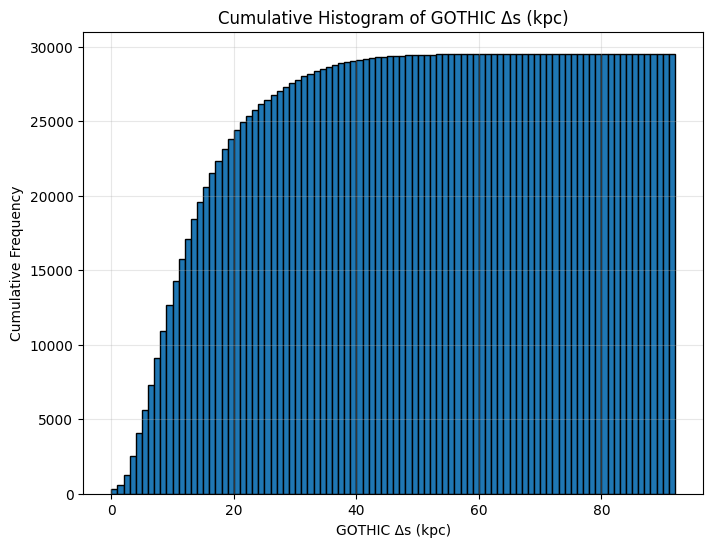

In [45]:
plt.figure(figsize=(8,6))

plt.hist(
    df['gothic_delta_s_kpc'].dropna(),
    bins=bins,
    cumulative=True,
    edgecolor='black'
)

plt.xlabel('GOTHIC Δs (kpc)')
plt.ylabel('Cumulative Frequency')
plt.title('Cumulative Histogram of GOTHIC Δs (kpc)')
plt.grid(alpha=0.3)

plt.show()

In [46]:
kpc_table.to_csv(
    "gothic_kpc_frequency_table.csv",
    index=False
)

print("Saved gothic_kpc_frequency_table.csv")

Saved gothic_kpc_frequency_table.csv




0.0-5.0      4042
5.0-0.0      8649
10.0-15.0    6888
15.0-20.0    4215
20.0-25.0    2336
25.0-30.0    1430
30.0-35.0    942
35.0-40.0    536
40.0-45.0    276
45.0-50.0    110
50.0-55.0    51
55.0-60.0    20
60.0-65.0    11
65.0-70.0    4
70.0-75.0    2
75.0-80.0    1
80.0-85.0    2
85.0-90.0    0
90.0-95.0    1